# 17. PSL Coach: which finger is wrong?

**Goal.** The app can say *which letter* a hand shows. A learner also needs to know *what to change* when the sign is not right yet.
The PSL Coach compares 19 easy-to-explain angles of the learner's hand (15 finger bends + 4 spreads between fingers)
with the angles of the same letter in the training photos (66 signers) and names the finger with the biggest difference.

Code: `src/coach.py` (the coach), `src/coach_eval.py` (this test). Live: sidebar → *Practice (Coach)*.

**No leakage.** The test is signer-wise (GroupKFold, 5 folds over the 66 training signers). The reference angles and the
static model are rebuilt on the training folds only. The sealed test set (`test.csv`) is **not** used.

In [1]:
import sys
sys.path.append("..")
import numpy as np
import pandas as pd
from src.coach import FEATURE_NAMES, CoachReference, Z_POLISH, Z_TIP
from src.config import PROCESSED_DATA_DIR

ref = CoachReference.from_csv(PROCESSED_DATA_DIR / "train.csv")
print("letters:", len(ref.letters), "| angles per hand:", len(FEATURE_NAMES), "| Z_TIP =", Z_TIP, "| Z_POLISH =", Z_POLISH)
table = pd.DataFrame({L: ref.median[L] for L in ["Alif", "Bay", "Seen", "Wao", "Lam"]}, index=FEATURE_NAMES).round(0)
table  # median angle in degrees (bend: 0 = straight)

letters: 36 | angles per hand: 19 | Z_TIP = 2.5 | Z_POLISH = 4.0


,Alif,Bay,Seen,Wao,Lam
bend_thumb_1,36.0,32.0,33.0,25.0,22.0
bend_thumb_2,25.0,85.0,59.0,15.0,9.0
bend_thumb_3,20.0,29.0,47.0,40.0,14.0
bend_index_1,46.0,28.0,45.0,40.0,29.0
bend_index_2,125.0,19.0,116.0,63.0,4.0
bend_index_3,20.0,4.0,15.0,26.0,3.0
bend_middle_1,43.0,12.0,43.0,37.0,55.0
bend_middle_2,134.0,20.0,130.0,68.0,105.0
bend_middle_3,38.0,4.0,31.0,32.0,18.0
bend_ring_1,44.0,13.0,45.0,31.0,58.0


## How the test works

We cannot ask 66 signers to make mistakes, so we make them on purpose on held-out photos:
one finger is bent **more** or **straightened** by θ degrees at its middle joint; nothing else changes.
Then we ask what the app would do (same logic as the live app):

1. The static model (same pipeline as the deployed model, with mirror augmentation) gives the probability of the target letter.
   If it is ≥ 0.60 the app says **correct**; otherwise it says **not right yet** and shows the coach's tips.
2. When a tip is shown: does it name the finger we changed? Does it say the right direction (bend more / straighten)?
3. On the unchanged (correct) photos: how often would the app show a wrong tip?

Chance level for naming the finger is 1 in 5 = 20%.

In [2]:
from src.coach_eval import run, summarize

summaries, by_finger = [], []
for theta in (25.0, 40.0, 60.0):
    res = run(theta=theta)
    s, b = summarize(res)
    s.insert(0, "theta_deg", theta)
    b.insert(0, "theta_deg", theta)
    summaries.append(s)
    by_finger.append(b)
summary = pd.concat(summaries, ignore_index=True)
by_finger = pd.concat(by_finger, ignore_index=True)
summary.to_csv("../results/coach_eval.csv", index=False)
by_finger.to_csv("../results/coach_eval_by_finger.csv", index=False)
summary.pivot(index="measure", columns="theta_deg", values="value").round(3)

theta_deg,25.0,40.0,60.0
measure,,,
'even better' tip: names the changed finger,0.630,0.871,0.937
all changed: coach names the changed finger (no model gate),0.350,0.690,0.865
caught: coach names the changed finger,0.347,0.630,0.848
caught: tip has the right direction,0.354,0.620,0.823
changed but accepted: 'even better' tip is shown,0.131,0.403,0.778
changed finger: app says not right yet,0.115,0.160,0.253
correct photo: a wrong tip is shown,0.053,0.053,0.053
correct photo: an 'even better' tip is shown,0.049,0.049,0.049
correct photo: app says correct (model accepts),0.919,0.919,0.919


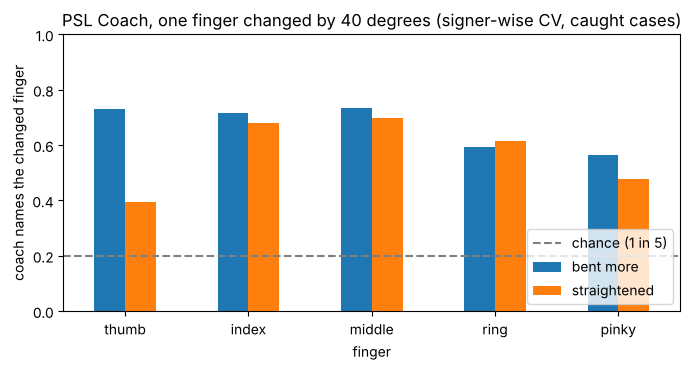

,theta_deg,finger,case,n,finger_ok,direction_ok
10,40.0,index,bent more,241,0.717842,0.763485
11,40.0,index,straightened,163,0.680982,0.570552
12,40.0,middle,bent more,290,0.734483,0.772414
13,40.0,middle,straightened,219,0.69863,0.598174
14,40.0,pinky,bent more,258,0.565891,0.488372
15,40.0,pinky,straightened,187,0.475936,0.411765
16,40.0,ring,bent more,281,0.594306,0.551601
17,40.0,ring,straightened,255,0.615686,0.576471
18,40.0,thumb,bent more,513,0.729045,0.816764
19,40.0,thumb,straightened,277,0.393502,0.389892


In [3]:
import matplotlib.pyplot as plt

b40 = by_finger[by_finger["theta_deg"] == 40.0]
piv = b40.pivot(index="finger", columns="case", values="finger_ok").reindex(["thumb", "index", "middle", "ring", "pinky"])
ax = piv.plot(kind="bar", figsize=(7, 3.8), rot=0)
ax.axhline(0.2, color="gray", linestyle="--", label="chance (1 in 5)")
ax.set_ylim(0, 1)
ax.set_ylabel("coach names the changed finger")
ax.set_title("PSL Coach, one finger changed by 40 degrees (signer-wise CV, caught cases)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig("../reports/figures/coach_eval_by_finger.png", dpi=150)
plt.show()
b40.round(3)

## What this means

- **Correct signs are left alone.** On correct photos of new signers the app shows a wrong tip only about 5% of the time
  (the model accepts 92% of them; for the other 8% the coach finds a big difference only now and then).
- **Real mistakes get the right finger.** When the model says "not right yet", the coach names the changed finger in
  about 63% of cases at 40 degrees and about 85% at 60 degrees (chance: 20%). The direction (bend more / straighten) is right
  in about 62% / 82%.
- **The coach sees what the model forgives.** The static model still accepts most hands with one finger 40 degrees off
  (84%), because it is trained to be tolerant. For those, the coach's optional "even better" tip appears in 40% of cases and
  names the right finger 87% of the time, while it appears on only about 5% of correct photos.
- **Weak spots.** Pinky and ring finger are harder (they move together in real hands), and "straighten your thumb" is the
  least reliable tip. Small mistakes (25 degrees) are usually not caught.
- **Limits.** The mistakes here are made by rotating one finger in the landmark data, not by real learners; the reference
  comes from studio photos; MediaPipe's depth (z) is noisy. A live check with real learners is still needed.